In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.close()
import matplotlib as mpl
from matplotlib import gridspec

mpl.rcParams['axes.spines.right'] = False
mpl.rcParams['axes.spines.top'] = False
import os
import pickle5 as pickle
import csv
from scipy.optimize import curve_fit

import import_ipynb
import ipynb.fs.full.ssiProjectModule as ssiMod

from tqdm.notebook import tqdm
import sys

import importlib as imp
imp.reload(ssiMod)

from scipy.stats import wilcoxon as w
from scipy.special import factorial
from scipy.stats import circmean
from scipy.stats import circstd
import math
import statsmodels.stats.api as sms

from multiprocessing import Pool
from functools import partial

from mpl_toolkits.axes_grid1.inset_locator import inset_axes

from datetime import datetime
import bisect


/home/cparis/anaconda3/lib/python3.7/site-packages/statsmodels/compat/pandas.py:49: FutureWarning: The Panel class is removed from pandas. Accessing it from the top-level namespace will also be removed in the next version
  data_klasses = (pandas.Series, pandas.DataFrame, pandas.Panel)


In [2]:
import numpy as np

def random_select(mask, x, rng=None):
    """
    Randomly choose x indices of mask where mask is True.

    Parameters
    ----------
    A : np.ndarray
        N-dimensional array of values.
    mask : np.ndarray (bool)
        Boolean array with the same shape as A.
    x : int
        Number of elements to sample (must be < number of True elements).
    rng : np.random.Generator, optional
        Random generator for reproducibility.

    Returns
    -------
    np.ndarray
        1D array of x randomly selected elements from A.
    """
    if rng is None:
        rng = np.random.default_rng()

    # Indices of True elements (flattened)
    true_indices = np.flatnonzero(mask)

    if x > len(true_indices):
        raise ValueError("x must be less than or equal to the number of True elements")

    # Randomly choose x of those indices without replacement
    chosen = rng.choice(true_indices, size=x, replace=False)

    # Return the corresponding values from A
    return chosen


In [3]:
nbins = 20

theta_step = 2
stim = np.arange(0,360,theta_step)
main_dir = '/home/cparis/00PhD/'

area_or_max = 'Area'
dat_dir_out = main_dir + f'Simulated Stretch/Analyze stretched quadruplets constrained by AREA or MAX/'

title = f'Stretch_BioQuads_multiplied_w_mean_g__theta_step={theta_step}_original_g_20240509_AREA.pkl'
# title = f'Stretch_BioQuads_multiplied_w_mean_g__theta_step={theta_step}_original_g_20240506_MAX.pkl'


with open(dat_dir_out+title, 'rb') as rick:
    data_dict = pickle.load(rick)
print(data_dict.keys())

dict_keys(['all_multipliers', 'all_quad_pars', 'all_quad_tc', 'all_ssis', 'all_quad_fwhm', 'exp_quad_list', 'all_quad_vm_fit_pars', 'all_quad_raw_mean_tcs', 'all_quad_raw_mean_stds', 'original_cell_idx_quads'])


In [4]:
quad_list = []

#array labelling the biological quadruplets
bio_quad_idx = []

for experiment_number in range(1,8,1):
    experiment_name = f'Exp{experiment_number}'
    datanfits = dict(np.load(main_dir+f'Analysis of {experiment_name}.npz'))
    print(datanfits['quadruplet_combos'].shape)
    quad_list += zip(np.full(len(datanfits['quadruplet_combos']), experiment_number), datanfits['quadruplet_combos'])
#     for each quadruplet
    for quad in datanfits['quadruplet_combos']:
        if quad.tolist() in datanfits['biological_quadruplets'].tolist():
            bio_quad_idx += [True]
        else:  bio_quad_idx+= [False]
bio_quad_idx = np.array(bio_quad_idx)    

data_dict['exp_quad_list'] = quad_list

exp_idx, quad = zip(*data_dict['exp_quad_list'])
quad = np.array(quad)
print('Number of bio quads in:')
for experiment_number in range(1,8,1):
    q = np.count_nonzero(np.array(exp_idx)[bio_quad_idx]==experiment_number)
    print(f'Experiment {experiment_number}: {q}',)

(120, 4)
(18, 4)
(72, 4)
(24, 4)
(160, 4)
(250, 4)
(4, 4)
Number of bio quads in:
Experiment 1: 21
Experiment 2: 0
Experiment 3: 9
Experiment 4: 0
Experiment 5: 33
Experiment 6: 19
Experiment 7: 2


In [5]:
bio_idx = np.where(data_dict['all_multipliers']==1.)[0][0]
maxMin_width_idx = data_dict['all_ssis'].min(axis = 2).argmax(axis=1)
maxAvg_width_idx = data_dict['all_ssis'].mean(axis = 2).argmax(axis=1)

maxMin_width_fwhm = np.array([data_dict['all_quad_fwhm'][i,j] for i,j in enumerate(maxMin_width_idx)])
maxAvg_width_fwhm = np.array([data_dict['all_quad_fwhm'][i,j] for i,j in enumerate(maxAvg_width_idx)])

bio_fwhms = data_dict['all_quad_fwhm'][:,bio_idx,:].round()

maxMin_width_idx = data_dict['all_ssis'].min(axis = 2).argmax(axis=1)
maxAvg_width_idx = data_dict['all_ssis'].mean(axis = 2).argmax(axis=1)

maxMin_SSI = np.array([data_dict['all_ssis'].min(axis = 2)[i,el] for i, el in enumerate(maxMin_width_idx)])
maxAvg_SSI = np.array([data_dict['all_ssis'].mean(axis = 2)[i,el] for i, el in enumerate(maxAvg_width_idx)])

perc_loss_maxmin = (maxMin_SSI-data_dict['all_ssis'].min(axis=2)[:,bio_idx])#/maxMin_SSI*100
perc_loss_maxavg = (maxAvg_SSI-data_dict['all_ssis'].mean(axis=2)[:,bio_idx])#/maxAvg_SSI*100

In [6]:
# non_prox_quads = np.sort(random_select(np.logical_not(bio_quad_idx), np.count_nonzero(bio_quad_idx)))
non_prox_quads = np.sort(np.random.choice(np.arange(bio_quad_idx.size), \
                                                   size=np.count_nonzero(bio_quad_idx), replace=False))
# print(non_prox_quads)
non_prox_quads = np.logical_not(bio_quad_idx)

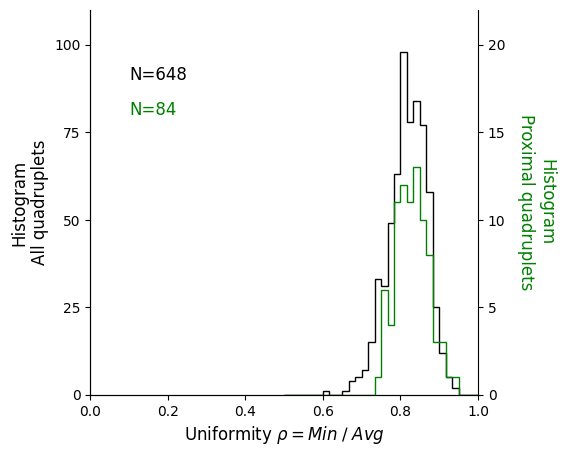

In [11]:
fig = plt.figure(figsize = (5,5))
ax1 = fig.add_subplot(111)
mpl.rcParams['axes.spines.right']=True
ax2 = ax1.twinx()

ro = data_dict['all_ssis'].min(axis=2)[:,bio_idx]/data_dict['all_ssis'].mean(axis=2)[:,bio_idx]
example_quads = [125,201]

ax1.hist(ro, \
         color = 'k',bins = 30, range=(0.5,1), histtype = 'step')
ax2.hist(ro[bio_quad_idx], \
         color = 'green', bins = 30, range=(0.5,1), histtype = 'step')
# ax1.scatter(ro[example_quads],[105,105], color = 'magenta', s=10)

ax1.set_xlim(0,1)
ax1.set_xticks(np.arange(0,1.1, 0.2))
ax1.set_xlabel(r'Uniformity $\rho= Min\;\slash\;Avg$', size = 12)
ax1.set_ylim(0,110)
ax1.set_yticks(np.arange(0,101, 25))
ax1.set_ylabel('Histogram\nAll quadruplets', color = 'k', size = 12)
ax2.set_ylim(0,22)
ax2.set_yticks(np.arange(0,21,5))
ax2.set_ylabel('Histogram\nProximal quadruplets', rotation=270, color = 'green', size = 12)
ax2.yaxis.set_label_coords(1.2, 0.5)
ax1.text(0.1, 90, 'N=648', size =12, c='k')
ax1.text(0.1, 80, 'N=84', size =12, c='g')
mpl.rcParams['axes.spines.right']=False

# fig.savefig('/home/cparis/Desktop/Uniformity_all_v_bio.jpg', bbox_inches = 'tight', dpi=300)

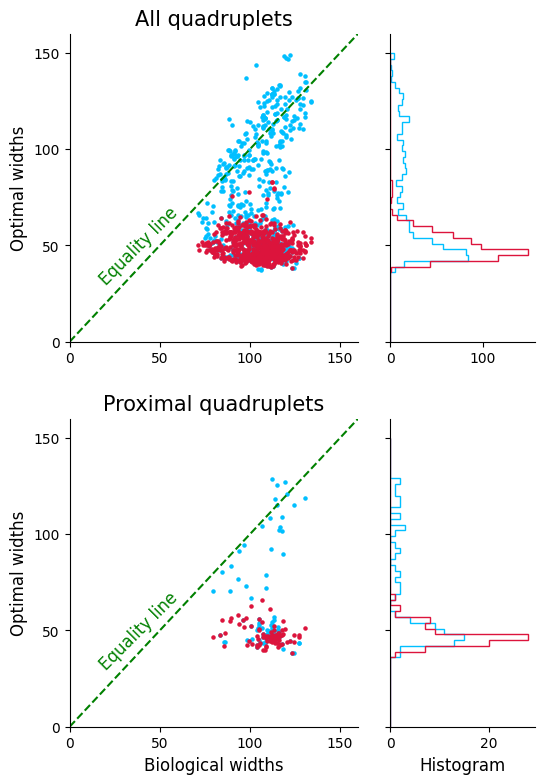

In [23]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np

bio_w    = bio_fwhms.mean(axis=1)
maxMin_w = maxMin_width_fwhm.mean(axis=1)
maxAvg_w = maxAvg_width_fwhm.mean(axis=1)

fig = plt.figure(figsize=(6,9))
gs = gridspec.GridSpec(2, 2, width_ratios=[2, 1], hspace=0.25, wspace=0.15)

ax_all     = fig.add_subplot(gs[0,0])
ax_all_h   = fig.add_subplot(gs[0,1], sharey=ax_all)
ax_bio     = fig.add_subplot(gs[1,0])
ax_bio_h   = fig.add_subplot(gs[1,1], sharey=ax_bio)

x = np.linspace(0, 160, 100)
bins = 50
ticks = np.arange(0, 151, 50)

# -------- all quadruplets --------
ax_all.scatter(bio_w, maxMin_w, color='deepskyblue', s=5)
ax_all.scatter(bio_w, maxAvg_w, color='crimson', s=5)
ax_all.plot(x, x, '--', color='green')
ax_all.text(15, 50, 'Equality line', color='green', rotation=45,
            fontsize=12, ha='left', va='center')
ax_all.set_xlim(0, 160)
ax_all.set_ylim(0, 160)
ax_all.set_ylabel('Optimal widths', size = 12)
ax_all.set_title('All quadruplets', size = 15)

ax_all_h.hist(maxMin_w, range = (0,150), bins=bins, orientation='horizontal',
              histtype='step', color='deepskyblue')
ax_all_h.hist(maxAvg_w, range = (0,150), bins=bins, orientation='horizontal',
              histtype='step', color='crimson')

ax_all_h.tick_params(labelleft=False)
ax_all.set_xticks(ticks)
ax_all.set_yticks(ticks)

ax_all_h.set_xticks(np.arange(0,120,100))
ax_all_h.set_yticks(ticks)

# -------- proximal quadruplets --------
ax_bio.scatter(bio_w[bio_quad_idx], maxMin_w[bio_quad_idx],
               color='deepskyblue', s=5)
ax_bio.scatter(bio_w[bio_quad_idx], maxAvg_w[bio_quad_idx],
               color='crimson', s=5)
ax_bio.plot(x, x, '--', color='green')
ax_bio.text(15, 50, 'Equality line', color='green', rotation=45,
            fontsize=12, ha='left', va='center')
ax_bio.set_xlim(0, 160)
ax_bio.set_ylim(0, 160)
ax_bio.set_xlabel('Biological widths', size = 12)
ax_bio.set_ylabel('Optimal widths', size = 12)
ax_bio.set_title('Proximal quadruplets', size = 15)

ax_bio_h.hist(maxMin_w[bio_quad_idx], range = (0,150), bins=bins,
              orientation='horizontal', histtype='step', color='deepskyblue')
ax_bio_h.hist(maxAvg_w[bio_quad_idx], range = (0,150), bins=bins,
              orientation='horizontal', histtype='step', color='crimson')

ax_bio_h.tick_params(labelleft=False)
ax_bio_h.set_xlabel('Histogram', size = 12)
ax_bio.set_xticks(ticks)
ax_bio.set_yticks(ticks)
ax_bio_h.set_yticks(ticks)
ax_bio_h.set_xticks(np.arange(0,30,20))
# fig.savefig(f'/home/cparis/Desktop/prox_v_bio_quad_scatters.jpg', bbox_inches='tight', dpi = 300)


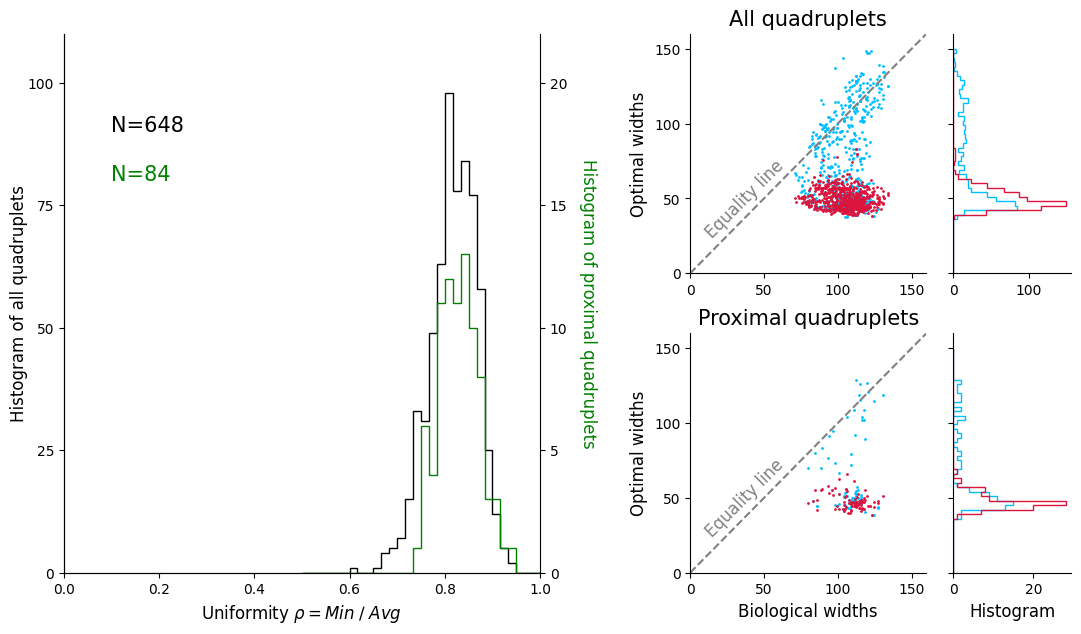

In [57]:
bio_w    = bio_fwhms.mean(axis=1)
maxMin_w = maxMin_width_fwhm.mean(axis=1)
maxAvg_w = maxAvg_width_fwhm.mean(axis=1)

fig = plt.figure(figsize=(13,7))

# ---- OUTER GRID (left histogram | right scatter panels) ----
outer = gridspec.GridSpec(1, 2, width_ratios=[5, 4], wspace=0.35)

# ============================================================
# LEFT PANEL (uniformity histogram)
# ============================================================

ax1 = fig.add_subplot(outer[0])
mpl.rcParams['axes.spines.right'] = True
ax2 = ax1.twinx()

ro = data_dict['all_ssis'].min(axis=2)[:,bio_idx] / \
     data_dict['all_ssis'].mean(axis=2)[:,bio_idx]

example_quads = [125,201]

ax1.hist(ro,
         color='k', bins=30, range=(0.5,1), histtype='step')

ax2.hist(ro[bio_quad_idx],
         color='green', bins=30, range=(0.5,1), histtype='step')

ax1.set_xlim(0,1)
ax1.set_xticks(np.arange(0,1.1,0.2))
ax1.set_xlabel(r'Uniformity $\rho= Min\;\slash\;Avg$', size=12)

ax1.set_ylim(0,110)
ax1.set_yticks(np.arange(0,101,25))
ax1.set_ylabel('Histogram of all quadruplets', color='k', size=12)

ax2.set_ylim(0,22)
ax2.set_yticks(np.arange(0,21,5))
ax2.set_ylabel('Histogram of proximal quadruplets',
               rotation=270, color='green', size=12)
ax1.yaxis.set_label_coords(-0.075, 0.5)
ax2.yaxis.set_label_coords(1.12, 0.5)

ax1.text(0.1,90,'N=648', size=15, c='k')
ax1.text(0.1,80,'N=84', size=15, c='g')

mpl.rcParams['axes.spines.right'] = False


# ============================================================
# RIGHT PANELS (your original gridspec)
# ============================================================

right = gridspec.GridSpecFromSubplotSpec(
    2, 2,
    subplot_spec=outer[1],
    width_ratios=[2,1],
    hspace=0.25,
    wspace=0.15
)

ax_all   = fig.add_subplot(right[0,0])
ax_all_h = fig.add_subplot(right[0,1], sharey=ax_all)

ax_bio   = fig.add_subplot(right[1,0])
ax_bio_h = fig.add_subplot(right[1,1], sharey=ax_bio)

x = np.linspace(0,160,100)
bins = 50
ticks = np.arange(0,151,50)

# ---- all quadruplets ----
ax_all.scatter(bio_w, maxMin_w, color='deepskyblue', s=1)
ax_all.scatter(bio_w, maxAvg_w, color='crimson', s=1)
ax_all.plot(x, x, '--', color='grey')

ax_all.text(0.05,0.15,'Equality line',
            color='grey', rotation=45, fontsize=12, transform = ax_all.transAxes)

ax_all.set_xlim(0,160)
ax_all.set_ylim(0,160)
ax_all.set_ylabel('Optimal widths', size=12)
ax_all.set_title('All quadruplets', size=15)

ax_all_h.hist(maxMin_w, range=(0,150), bins=bins,
              orientation='horizontal', histtype='step',
              color='deepskyblue')

ax_all_h.hist(maxAvg_w, range=(0,150), bins=bins,
              orientation='horizontal', histtype='step',
              color='crimson')

ax_all_h.tick_params(labelleft=False)

ax_all.set_xticks(ticks)
ax_all.set_yticks(ticks)

ax_all_h.set_xticks(np.arange(0,120,100))
ax_all_h.set_yticks(ticks)

# ---- proximal quadruplets ----
ax_bio.scatter(bio_w[bio_quad_idx],
               maxMin_w[bio_quad_idx],
               color='deepskyblue', s=1)

ax_bio.scatter(bio_w[bio_quad_idx],
               maxAvg_w[bio_quad_idx],
               color='crimson', s=1)

ax_bio.plot(x, x, '--', color='grey')

ax_bio.text(0.05,0.15,'Equality line',
            color='grey', rotation=45, fontsize=12, transform = ax_bio.transAxes)

ax_bio.set_xlim(0,160)
ax_bio.set_ylim(0,160)

ax_bio.set_xlabel('Biological widths', size=12)
ax_bio.set_ylabel('Optimal widths', size=12)

ax_bio.set_title('Proximal quadruplets', size=15)

ax_bio_h.hist(maxMin_w[bio_quad_idx],
              range=(0,150), bins=bins,
              orientation='horizontal',
              histtype='step',
              color='deepskyblue')

ax_bio_h.hist(maxAvg_w[bio_quad_idx],
              range=(0,150), bins=bins,
              orientation='horizontal',
              histtype='step',
              color='crimson')

ax_bio_h.tick_params(labelleft=False)

ax_bio_h.set_xlabel('Histogram', size=12)

ax_bio.set_xticks(ticks)
ax_bio.set_yticks(ticks)

ax_bio_h.set_yticks(ticks)
ax_bio_h.set_xticks(np.arange(0,30,20))

plt.show()

Text(0.5, 0, 'Proximal quadruplets\n(N=84)')

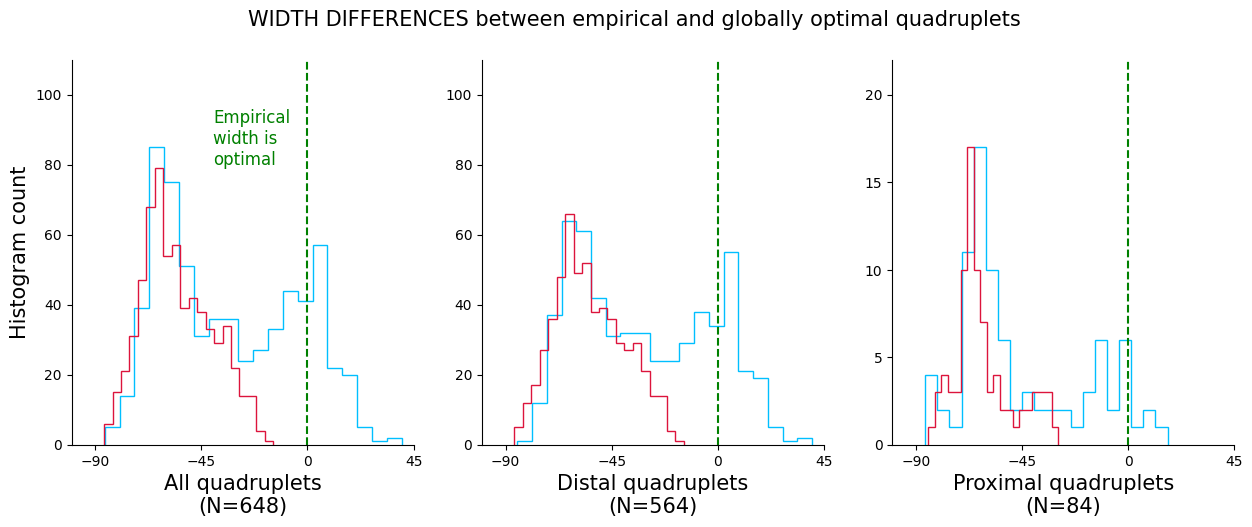

In [28]:
fig = plt.figure(figsize = (15,5))
gs = gridspec.GridSpec(1,3)
ax_all = fig.add_subplot(gs[0])
ax_nonprox = fig.add_subplot(gs[1])
ax_bio = fig.add_subplot(gs[2])

fig.suptitle('WIDTH DIFFERENCES between empirical and globally optimal quadruplets', size=15)

# ---------- ALL QUADRUPLETS ----------
ax_all.hist(-(bio_fwhms.mean(axis=1) - maxMin_width_fwhm.mean(axis=1)),
            bins=nbins, histtype='step', color='deepskyblue')
ax_all.hist(-(bio_fwhms.mean(axis=1) - maxAvg_width_fwhm.mean(axis=1)),
            bins=nbins, histtype='step', color='crimson')

ax_all.axvline(0, linestyle='dashed', color='green')
ax_all.text(-40, 80, 'Empirical\nwidth is\noptimal',
            color='green', fontsize=12, transform=ax_all.transData)

ax_all.set_xlim(-100, 45)
ax_all.set_xticks(np.arange(-90, 55, 45))
ax_all.set_ylim(0, 110)
ax_all.set_yticks(np.arange(0, 101, 20))
ax_all.set_xlabel(f'All quadruplets\n(N={bio_quad_idx.size})', size=15)
ax_all.set_ylabel('Histogram count', size=15)


# ---------- DISTAL (NON-PROXIMAL) ----------
ax_nonprox.hist(-(bio_fwhms.mean(axis=1)[non_prox_quads]
                  - maxMin_width_fwhm.mean(axis=1)[non_prox_quads]),
                bins=nbins, histtype='step', color='deepskyblue')
ax_nonprox.hist(-(bio_fwhms.mean(axis=1)[non_prox_quads]
                  - maxAvg_width_fwhm.mean(axis=1)[non_prox_quads]),
                bins=nbins, histtype='step', color='crimson')

ax_nonprox.axvline(0, linestyle='dashed', color='green')
# ax_nonprox.text(-40, 80, 'Empirical\nwidth is\noptimal',
#                 color='green', fontsize=12, transform=ax_nonprox.transData)

ax_nonprox.set_xlim(-100, 45)
ax_nonprox.set_xticks(np.arange(-90, 55, 45))
ax_nonprox.set_ylim(0, 110)
ax_nonprox.set_yticks(np.arange(0, 101, 20))
ax_nonprox.set_xlabel(f'Distal quadruplets\n(N={np.count_nonzero(non_prox_quads)})',
                      size=15)


# ---------- PROXIMAL (BIOLOGICAL) ----------
ax_bio.hist(-(bio_fwhms.mean(axis=1)[bio_quad_idx]
              - maxMin_width_fwhm.mean(axis=1)[bio_quad_idx]),
            bins=nbins, histtype='step', color='deepskyblue')
ax_bio.hist(-(bio_fwhms.mean(axis=1)[bio_quad_idx]
              - maxAvg_width_fwhm.mean(axis=1)[bio_quad_idx]),
            bins=nbins, histtype='step', color='crimson')

ax_bio.axvline(0, linestyle='dashed', color='green')
# ax_bio.text(-40, 16, 'Empirical\nwidth is\noptimal',
#             color='green', fontsize=12, transform=ax_bio.transData)

ax_bio.set_xlim(-100, 45)
ax_bio.set_xticks(np.arange(-90, 55, 45))
ax_bio.set_yticks(np.arange(0, 26, 5))
ax_bio.set_ylim(0, 22)
ax_bio.set_xlabel(f'Proximal quadruplets\n(N={np.count_nonzero(bio_quad_idx)})',
                  size=15)
# fig.savefig('/home/cparis/Desktop/Width_comparison_all_v_bio.jpg', bbox_inches = 'tight', dpi=300)

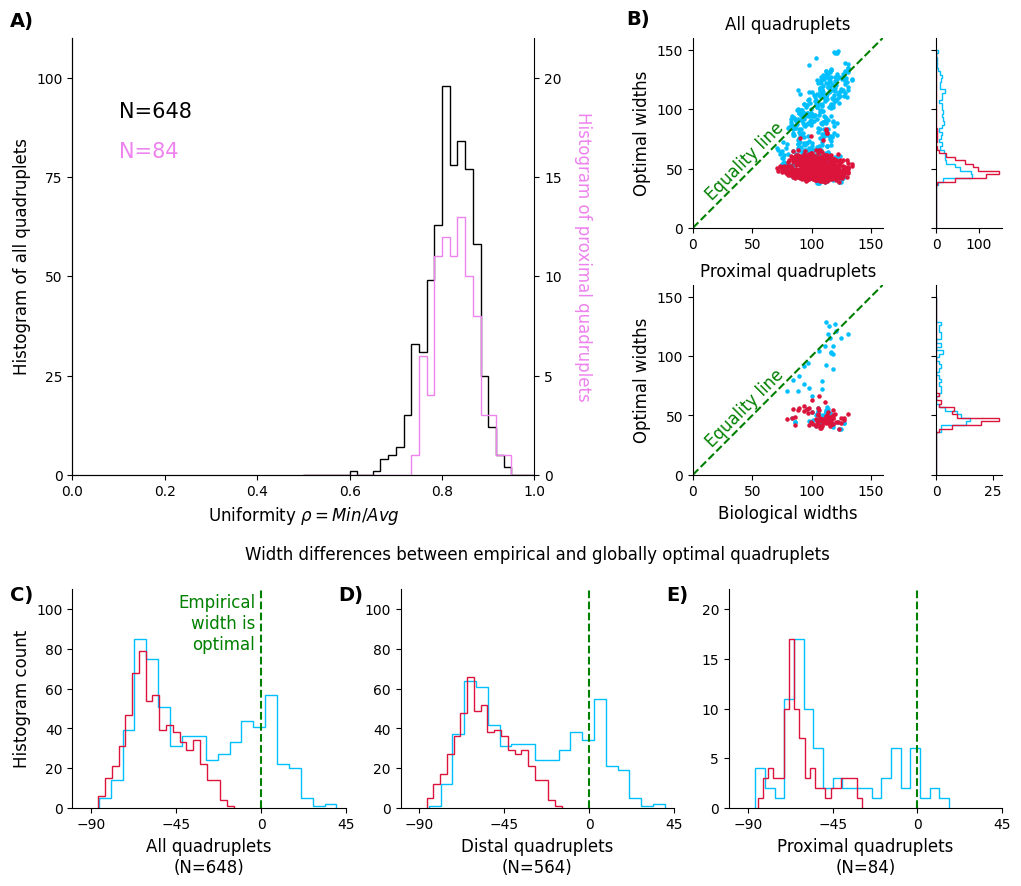

In [180]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import matplotlib as mpl

fig = plt.figure(figsize=(12,10))

# ==========================================================
# OUTER LAYOUT
# ==========================================================
outer = gridspec.GridSpec(
    2,2,
    height_ratios=[2,1],
    width_ratios=[4,3],
    hspace=0.35,
    wspace=0.3
)

# ==========================================================
# TOP LEFT — UNIFORMITY HISTOGRAM
# ==========================================================
ax1 = fig.add_subplot(outer[0,0])
# ax1.set_box_aspect(1)

mpl.rcParams['axes.spines.right']=True
ax2 = ax1.twinx()

ro = data_dict['all_ssis'].min(axis=2)[:,bio_idx] / \
     data_dict['all_ssis'].mean(axis=2)[:,bio_idx]

ax1.hist(ro, color='k', bins=30, range=(0.5,1), histtype='step')
ax2.hist(ro[bio_quad_idx], color='violet', bins=30, range=(0.5,1), histtype='step')

ax1.set_xlim(0,1)
ax1.set_xticks(np.arange(0,1.1,0.2))
ax1.set_xlabel(r'Uniformity $\rho = Min/Avg$', size=12)

ax1.set_ylim(0,110)
ax1.set_yticks(np.arange(0,101,25))
ax1.set_ylabel('Histogram of all quadruplets', size=12)

ax2.set_ylim(0,22)
ax2.set_yticks(np.arange(0,21,5))
ax2.set_ylabel('Histogram of proximal quadruplets',
               rotation=270, color='violet', size=12)

ax2.yaxis.set_label_coords(1.125,0.5)

ax1.text(0.1,90,'N=648', size=15, c='k')
ax1.text(0.1,80,'N=84', size=15, c='violet')

mpl.rcParams['axes.spines.right']=False

ax1.text(-0.135, 1.06, 'A)', transform=ax1.transAxes, ha='left', va='top', fontsize=14, fontweight='bold')

# ==========================================================
# TOP RIGHT — SCATTER + SIDE HISTOGRAMS
# ==========================================================
right = gridspec.GridSpecFromSubplotSpec(
    2,2,
    subplot_spec=outer[0,1],
    width_ratios=[4,1],
    hspace=0.3,
    wspace=0.1
)

ax_all   = fig.add_subplot(right[0,0])
ax_all_h = fig.add_subplot(right[0,1], sharey=ax_all)

ax_bio   = fig.add_subplot(right[1,0])
ax_bio_h = fig.add_subplot(right[1,1], sharey=ax_bio)

bio_w    = bio_fwhms.mean(axis=1)
maxMin_w = maxMin_width_fwhm.mean(axis=1)
maxAvg_w = maxAvg_width_fwhm.mean(axis=1)

x = np.linspace(0,160,100)
bins = 50
ticks = np.arange(0,151,50)

# ----- ALL QUADRUPLETS
ax_all.scatter(bio_w, maxMin_w, color='deepskyblue', s=5)
ax_all.scatter(bio_w, maxAvg_w, color='crimson', s=5)

ax_all.plot(x,x,'--',color='green')
ax_all.text(0.05,0.15,'Equality line', color='green', rotation=45, fontsize=12, transform = ax_all.transAxes)

ax_all.set_xlim(0,160)
ax_all.set_ylim(0,160)

ax_all.set_ylabel('Optimal widths', size = 12)
ax_all.set_title('All quadruplets')

ax_all_h.hist(maxMin_w, range=(0,150), bins=bins,
              orientation='horizontal', histtype='step',
              color='deepskyblue')

ax_all_h.hist(maxAvg_w, range=(0,150), bins=bins,
              orientation='horizontal', histtype='step',
              color='crimson')

ax_all_h.tick_params(labelleft=False)

ax_all.set_xticks(ticks)
ax_all.set_yticks(ticks)
ax_all.set_box_aspect(1)
ax_bio.set_box_aspect(1)

# ----- PROXIMAL
ax_bio.scatter(bio_w[bio_quad_idx],
               maxMin_w[bio_quad_idx],
               color='deepskyblue', s=5)

ax_bio.scatter(bio_w[bio_quad_idx],
               maxAvg_w[bio_quad_idx],
               color='crimson', s=5)

ax_bio.plot(x,x,'--',color='green')

ax_bio.text(0.05,0.15,'Equality line',
            color='green', rotation=45,
            fontsize=12, transform=ax_bio.transAxes)

ax_bio.set_xlim(0,160)
ax_bio.set_ylim(0,160)

ax_bio.set_xlabel('Biological widths', size = 12)
ax_bio.set_ylabel('Optimal widths', size = 12)

ax_bio.set_title('Proximal quadruplets')

ax_bio_h.hist(maxMin_w[bio_quad_idx],
              range=(0,150), bins=bins,
              orientation='horizontal',
              histtype='step',
              color='deepskyblue')

ax_bio_h.hist(maxAvg_w[bio_quad_idx],
              range=(0,150), bins=bins,
              orientation='horizontal',
              histtype='step',
              color='crimson')

ax_bio_h.tick_params(labelleft=False)

ax_bio.set_xticks(ticks)
ax_bio.set_yticks(ticks)

ax_all.text(-0.35, 1.15, 'B)', transform=ax_all.transAxes, ha='left', va='top', fontsize=14, fontweight='bold')
# ==========================================================
# BOTTOM — 3 HISTOGRAMS
# ==========================================================
bottom = gridspec.GridSpecFromSubplotSpec(
    1,3,
    subplot_spec=outer[1,:],
    wspace=0.2
)

ax_all_hist     = fig.add_subplot(bottom[0])
ax_nonprox_hist = fig.add_subplot(bottom[1])
ax_bio_hist     = fig.add_subplot(bottom[2])

# for ax in [ax_all_hist, ax_nonprox_hist, ax_bio_hist]:
#     ax.set_box_aspect(1)

# ----- ALL
ax_all_hist.hist(-(bio_fwhms.mean(axis=1) - maxMin_width_fwhm.mean(axis=1)),
                 bins=nbins, histtype='step', color='deepskyblue')

ax_all_hist.hist(-(bio_fwhms.mean(axis=1) - maxAvg_width_fwhm.mean(axis=1)),
                 bins=nbins, histtype='step', color='crimson')

ax_all_hist.axvline(0, linestyle='dashed', color='green')
ax_all_hist.text(-3, 80, 'Empirical\nwidth is\noptimal',
            color='green', ha='right', fontsize=12, transform=ax_all_hist.transData)

ax_all_hist.set_xlim(-100,45)
ax_all_hist.set_xticks(np.arange(-90,55,45))
ax_all_hist.set_ylim(0,110)
ax_all_hist.set_yticks(np.arange(0,101,20))

ax_all_hist.set_xlabel(f'All quadruplets\n(N={bio_quad_idx.size})', size = 12)
ax_all_hist.set_ylabel('Histogram count', size =12)


# ----- DISTAL
bbox = ax_nonprox_hist.get_position()

fig.text(bbox.x0 + bbox.width/2,
    bbox.y1 + 0.03,
    'Width differences between empirical and globally optimal quadruplets',
    ha='center',
    fontsize=12)
ax_nonprox_hist.hist(-(bio_fwhms.mean(axis=1)[non_prox_quads]
                       - maxMin_width_fwhm.mean(axis=1)[non_prox_quads]),
                     bins=nbins, histtype='step', color='deepskyblue')

ax_nonprox_hist.hist(-(bio_fwhms.mean(axis=1)[non_prox_quads]
                       - maxAvg_width_fwhm.mean(axis=1)[non_prox_quads]),
                     bins=nbins, histtype='step', color='crimson')

ax_nonprox_hist.axvline(0, linestyle='dashed', color='green')

ax_nonprox_hist.set_xlim(-100,45)
ax_nonprox_hist.set_xticks(np.arange(-90,55,45))
ax_nonprox_hist.set_ylim(0,110)

ax_nonprox_hist.set_xlabel(
    f'Distal quadruplets\n(N={np.count_nonzero(non_prox_quads)})', size = 12
)


# ----- PROXIMAL
ax_bio_hist.hist(-(bio_fwhms.mean(axis=1)[bio_quad_idx]
                   - maxMin_width_fwhm.mean(axis=1)[bio_quad_idx]),
                 bins=nbins, histtype='step', color='deepskyblue')

ax_bio_hist.hist(-(bio_fwhms.mean(axis=1)[bio_quad_idx]
                   - maxAvg_width_fwhm.mean(axis=1)[bio_quad_idx]),
                 bins=nbins, histtype='step', color='crimson')

ax_bio_hist.axvline(0, linestyle='dashed', color='green')

ax_bio_hist.set_xlim(-100,45)
ax_bio_hist.set_xticks(np.arange(-90,55,45))
ax_bio_hist.set_ylim(0,22)

ax_bio_hist.set_xlabel(
    f'Proximal quadruplets\n(N={np.count_nonzero(bio_quad_idx)})', size = 12
)

ax_all_hist.text(-0.228,1.02, 'C)', transform=ax_all_hist.transAxes, ha='left', va='top', fontsize=14, fontweight='bold')
ax_nonprox_hist.text(-0.228,1.02, 'D)', transform=ax_nonprox_hist.transAxes, ha='left', va='top', fontsize=14, fontweight='bold')
ax_bio_hist.text(-0.228,1.02, 'E)', transform=ax_bio_hist.transAxes, ha='left', va='top', fontsize=14, fontweight='bold')

plt.savefig('Proximal_cells_comparison.jpg', bbox_inches = 'tight', dpi= 400)

Text(0.5, 0, 'Proximal quadruplets\n(N=84)')

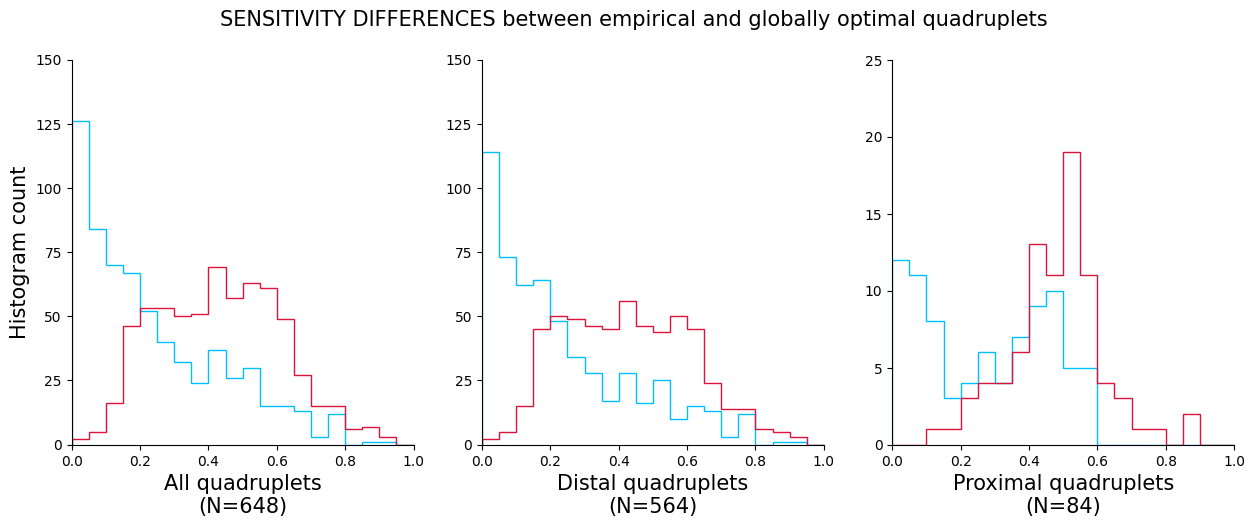

In [24]:
fig = plt.figure(figsize = (15,5))
gs = gridspec.GridSpec(1,3)
ax_all = fig.add_subplot(gs[0])
ax_nonprox = fig.add_subplot(gs[1])
ax_bio = fig.add_subplot(gs[2])

fig.suptitle('SENSITIVITY DIFFERENCES between empirical and globally optimal quadruplets', size =15)

ax_all.hist(perc_loss_maxmin, range = (0,1),\
            bins = nbins, histtype ='step', color = 'deepskyblue')
ax_all.hist(perc_loss_maxavg, range = (0,1),\
            bins = nbins, histtype ='step', color = 'crimson')
# ax_all.axvline(0, linestyle='dashed', color = 'green')
# ax_all.text(5, 80, 'Empirical\nwidth is\noptimal', color = 'green', fontsize = 12, transform = ax_all.transData)

ax_all.set_xlim(0,1)
ax_all.set_xticks(np.arange(0,1.01,0.2))
ax_all.set_ylim(0,150)
ax_all.set_yticks(np.arange(0,151,25))
ax_all.set_xlabel(f'All quadruplets\n(N={bio_quad_idx.size})', size = 15)
ax_all.set_ylabel('Histogram count', size = 15)

ax_nonprox.hist(perc_loss_maxmin[non_prox_quads], range = (0,1),\
                bins = nbins, histtype ='step', color = 'deepskyblue')
ax_nonprox.hist(perc_loss_maxavg[non_prox_quads], range = (0,1),\
                bins = nbins, histtype ='step', color = 'crimson')
ax_nonprox.set_xlim(0,1)
ax_nonprox.set_xticks(np.arange(0,1.1,0.2))
ax_nonprox.set_ylim(0,150)
ax_nonprox.set_yticks(np.arange(0,151,25))
ax_nonprox.set_xlabel(f'Distal quadruplets\n(N={np.count_nonzero(non_prox_quads)})', size = 15)

ax_bio.hist(perc_loss_maxmin[bio_quad_idx], range = (0,1),\
            bins = nbins, histtype ='step', color = 'deepskyblue')
ax_bio.hist(perc_loss_maxavg[bio_quad_idx], range = (0,1),\
            bins = nbins, histtype ='step', color = 'crimson')
ax_bio.set_xlim(0,1)
ax_bio.set_xticks(np.arange(0,1.1,0.2))
ax_bio.set_ylim(0,25)
ax_bio.set_yticks(np.arange(0,26,5))
ax_bio.set_xlabel(f'Proximal quadruplets\n(N={np.count_nonzero(bio_quad_idx)})', size = 15)
# fig.savefig('/home/cparis/Desktop/Sensitivity_comparison_all_v_bio.jpg', bbox_inches = 'tight', dpi=300)

In [25]:
from scipy.signal import savgol_filter
from scipy.signal import find_peaks
tolerance = 0.01

##  SAVITZKY - GOLAY FILTER
ssi_min_filt = np.array([savgol_filter(ssi_evol_raw,5,3) for \
                         ssi_evol_raw in data_dict['all_ssis'].min(axis=2)])
ssi_avg_filt = np.array([savgol_filter(ssi_evol_raw,5,3) for \
                         ssi_evol_raw in data_dict['all_ssis'].mean(axis=2)])
    
optima_min = np.array([find_peaks(el[data_dict['all_quad_fwhm'][i,0:len(el)].mean(axis=1)<=180], \
                                        prominence=np.std(el)*tolerance)[0][-1] \
                       for i,el in enumerate(ssi_min_filt)])
optima_avg = np.array([find_peaks(el[data_dict['all_quad_fwhm'][i, 0:len(el)].mean(axis=1)<=180], \
                                        prominence=np.std(el)*tolerance)[0][-1] for i,el in \
                  enumerate(ssi_avg_filt)])

optima_widths_min = np.array([data_dict['all_quad_fwhm'][i,el].mean() for i,el in enumerate(optima_min)])
optima_widths_avg = np.array([data_dict['all_quad_fwhm'][i,el].mean() for i,el in enumerate(optima_avg)])

crawl_loss_maxmin = maxMin_SSI-np.array([data_dict['all_ssis'][i,el].min() for i,el in enumerate(optima_min)])
crawl_loss_maxavg = maxAvg_SSI-np.array([data_dict['all_ssis'][i,el].mean() for i,el in enumerate(optima_min)])

/home/cparis/anaconda3/lib/python3.7/site-packages/scipy/signal/_arraytools.py:45: FutureWarning: Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.
  b = a[a_slice]


Text(0.5, 0, 'Proximal quadruplets\n(N=84)')

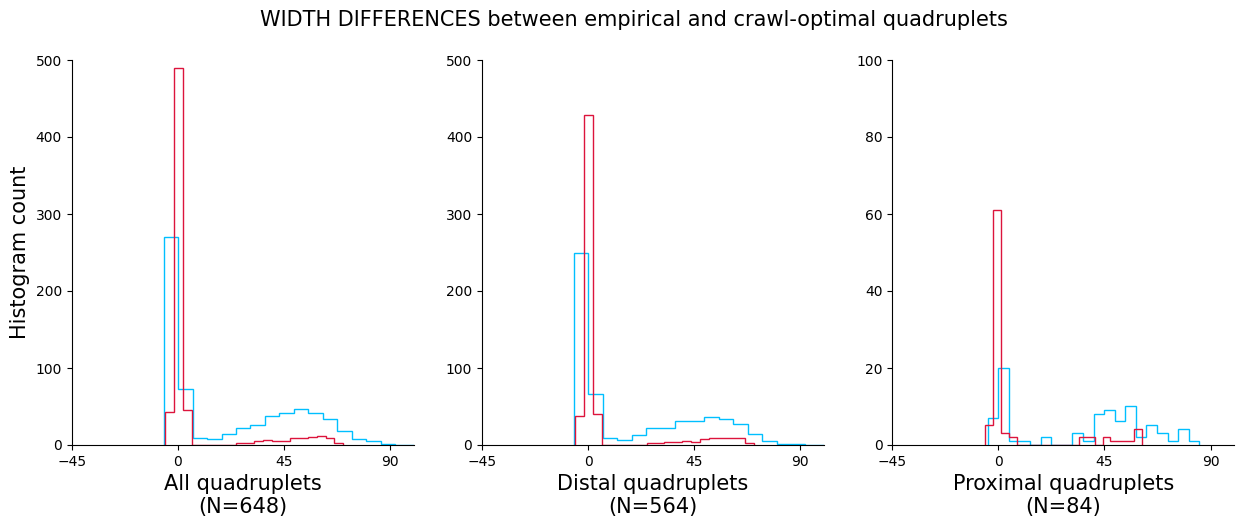

In [26]:
fig = plt.figure(figsize = (15,5))
gs = gridspec.GridSpec(1,3)
ax_all = fig.add_subplot(gs[0])
ax_nonprox = fig.add_subplot(gs[1])
ax_bio = fig.add_subplot(gs[2])

fig.suptitle('WIDTH DIFFERENCES between empirical and crawl-optimal quadruplets', size =15)

ax_all.hist(optima_widths_min-maxMin_width_fwhm.mean(axis=1), bins = nbins, \
            histtype ='step', color = 'deepskyblue')
ax_all.hist(optima_widths_avg-maxAvg_width_fwhm.mean(axis=1), bins = nbins, \
            histtype ='step', color = 'crimson')
# ax_all.axvline(0, linestyle='dashed', color = 'green')
# ax_all.text(5, 80, 'Empirical\nwidth is\noptimal', color = 'green', fontsize = 12, transform = ax_all.transData)

ax_all.set_xlim(-45,100)
ax_all.set_xticks(np.arange(-45,135,45))
ax_all.set_ylim(0,500)
ax_all.set_yticks(np.arange(0,501,100))
ax_all.set_xlabel(f'All quadruplets\n(N={bio_quad_idx.size})', size = 15)
ax_all.set_ylabel('Histogram count', size = 15)

ax_nonprox.hist(optima_widths_min[non_prox_quads]-maxMin_width_fwhm.mean(axis=1)[non_prox_quads], \
                bins = nbins, histtype ='step', color = 'deepskyblue')
ax_nonprox.hist(optima_widths_avg[non_prox_quads]-maxAvg_width_fwhm.mean(axis=1)[non_prox_quads], \
                bins = nbins, histtype ='step', color = 'crimson')
ax_nonprox.set_xlim(-45,100)
ax_nonprox.set_xticks(np.arange(-45,135,45))
ax_nonprox.set_ylim(0,500)
ax_nonprox.set_yticks(np.arange(0,501,100))
ax_nonprox.set_xlabel(f'Distal quadruplets\n(N={np.count_nonzero(non_prox_quads)})', size = 15)

ax_bio.hist(optima_widths_min[bio_quad_idx]-maxMin_width_fwhm.mean(axis=1)[bio_quad_idx], bins = nbins, \
            histtype ='step', color = 'deepskyblue')
ax_bio.hist(optima_widths_avg[bio_quad_idx]-maxAvg_width_fwhm.mean(axis=1)[bio_quad_idx], bins = nbins, \
            histtype ='step', color = 'crimson')
ax_bio.set_xlim(-45,100)
ax_bio.set_xticks(np.arange(-45,135,45))
ax_bio.set_ylim(0,100)
ax_bio.set_yticks(np.arange(0,101,20))
ax_bio.set_xlabel(f'Proximal quadruplets\n(N={np.count_nonzero(bio_quad_idx)})', size = 15)

Text(0.5, 0, 'Proximal quadruplets\n(N=84)')

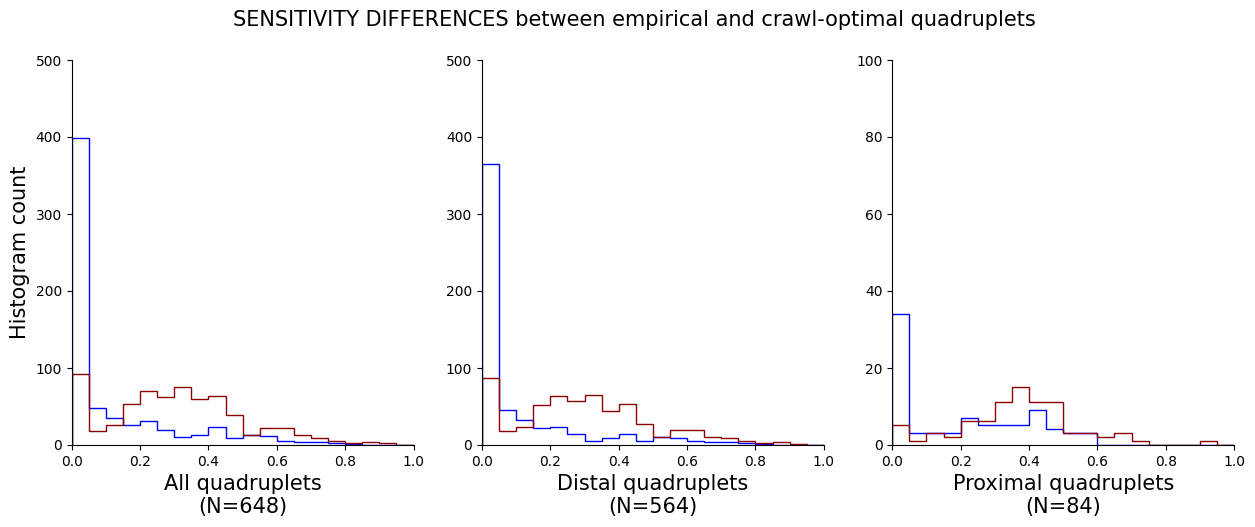

In [27]:
fig = plt.figure(figsize = (15,5))
gs = gridspec.GridSpec(1,3)
ax_all = fig.add_subplot(gs[0])
ax_nonprox = fig.add_subplot(gs[1])
ax_bio = fig.add_subplot(gs[2])

fig.suptitle('SENSITIVITY DIFFERENCES between empirical and crawl-optimal quadruplets', size =15)

ax_all.hist(crawl_loss_maxmin, range = (0,1), \
            bins = nbins, histtype ='step', color = 'blue')
ax_all.hist(crawl_loss_maxavg, range = (0,1), \
            bins = nbins, histtype ='step', color = 'darkred')
# ax_all.axvline(0, linestyle='dashed', color = 'green')
# ax_all.text(5, 80, 'Empirical\nwidth is\noptimal', color = 'green', fontsize = 12, transform = ax_all.transData)

ax_all.set_xlim(0,1)
ax_all.set_xticks(np.arange(0,1.1,0.2))
ax_all.set_ylim(0,500)
ax_all.set_yticks(np.arange(0,501,100))
ax_all.set_xlabel(f'All quadruplets\n(N={bio_quad_idx.size})', size = 15)
ax_all.set_ylabel('Histogram count', size = 15)

ax_nonprox.hist(crawl_loss_maxmin[non_prox_quads], range = (0,1), \
                bins = nbins, histtype ='step', color = 'blue')
ax_nonprox.hist(crawl_loss_maxavg[non_prox_quads], range = (0,1), \
                bins = nbins, histtype ='step', color = 'darkred')
ax_nonprox.set_xlim(0,1)
ax_nonprox.set_xticks(np.arange(0,1.1,0.2))
ax_nonprox.set_ylim(0,500)
ax_nonprox.set_yticks(np.arange(0,501,100))
ax_nonprox.set_xlabel(f'Distal quadruplets\n(N={np.count_nonzero(non_prox_quads)})', size = 15)

ax_bio.hist(crawl_loss_maxmin[bio_quad_idx], range = (0,1), \
            bins = nbins, histtype ='step', color = 'blue')
ax_bio.hist(crawl_loss_maxavg[bio_quad_idx], range = (0,1), \
            bins = nbins, histtype ='step', color = 'darkred')
ax_bio.set_xlim(0,1)
ax_bio.set_xticks(np.arange(0,1.1,0.2))
ax_bio.set_ylim(0,100)
ax_bio.set_yticks(np.arange(0,101,20))
ax_bio.set_xlabel(f'Proximal quadruplets\n(N={np.count_nonzero(bio_quad_idx)})', size = 15)
# fig.savefig('/home/cparis/Desktop/Width_comparison_all_v_bio__crawl.jpg', bbox_inches = 'tight', dpi=300)